In [ ]:
import os
# Auto-resolve repository root whether executed from repository root or notebooks/ directory
if not os.path.exists('data/pubmed_dataset.csv') and os.path.exists('../data/pubmed_dataset.csv'):
    os.chdir('..')
print('Active working directory:', os.getcwd())


# Disease-Specific Knowledge Mapping (Unsupervised Clustering) - BioBERT Pipeline

This notebook implements an **unsupervised** pipeline for grouping biomedical documents. It replaces TF-IDF with **BioBERT embeddings** to capture deep semantic relationships. It determines the optimal number of clusters using the Elbow Method and automatically maps the resulting clusters to disease topics based on extracted keywords. 

**All results (CSVs and PNGs) are exported directly to the `BioBERT Results/` directory.**

## Pipeline Overview:
1. **Data Loading**: Load biomedical text data.
2. **Preprocessing**: Clean and tokenize text data.
3. **BioBERT Feature Extraction**: Transform text into dense semantic embeddings using BioBERT.
4. **Contrastive Learning (Self-Supervised)**: Compute similarity-based embeddings using pseudo-class centroids.
5. **UMAP Dimensionality Reduction**: Reduce feature space while preserving structure.
6. **Clustering**: Group documents using KMeans, HDBSCAN, and Hierarchical Clustering using an automatically discovered K via the Elbow Method.
7. **BERTopic / Topic Analysis**: Extract topic keywords for each cluster.
8. **Evaluation Metrics**: Assess clustering quality.
9. **Keyword Extraction per cluster**: Find top keywords per cluster.
10. **Disease Knowledge Mapping**: Automatically name and map clusters to disease topics based on their top keywords.
11. **Visualization**: Plot final UMAP clusters with automatically generated disease labels.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os, re, nltk, torch
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.preprocessing import normalize
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score
from transformers import AutoTokenizer, AutoModel
import umap
import hdbscan
import warnings
from tqdm import tqdm

warnings.filterwarnings('ignore')

# ── Setup ──────────────────────────────────────────────────────────────────────
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 7)
RES = 'results/biobert' if os.path.exists('results') else ('../results/biobert' if os.path.exists('../results') else 'results/biobert')
os.makedirs(RES, exist_ok=True)
nltk.download('stopwords', quiet=True)
nltk.download('punkt',     quiet=True)
nltk.download('punkt_tab', quiet=True)
print("Libraries imported and environment setup.")


d:\Spring 25-26\IDS\About Project\ICCA\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Libraries imported and environment setup.


## Step 1: Data Loading


=== STEP 1: Data Loading ===
Dataset loaded: 14065 documents


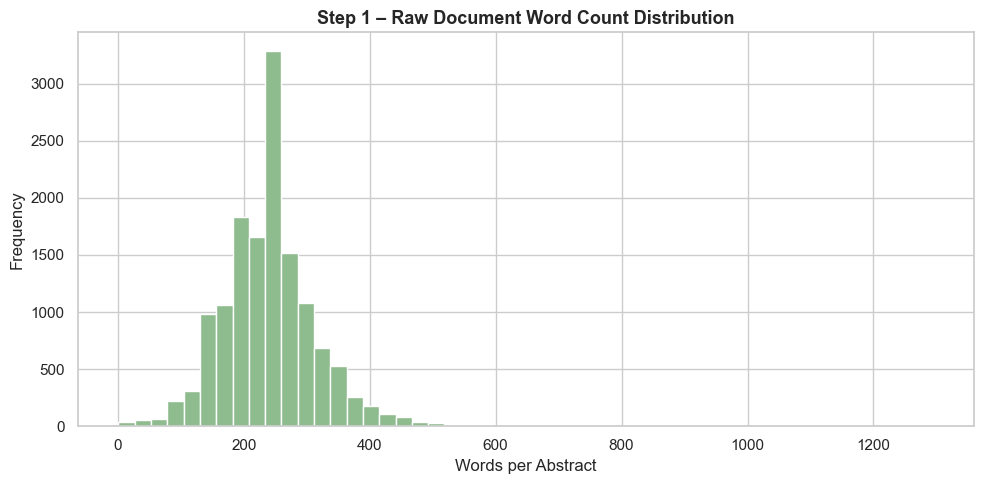

In [2]:
print("\n=== STEP 1: Data Loading ===")
data_path = 'data/pubmed_dataset.csv' if os.path.exists('data/pubmed_dataset.csv') else ('../data/pubmed_dataset.csv' if os.path.exists('../data/pubmed_dataset.csv') else 'pubmed_dataset.csv')
df = pd.read_csv(data_path)
print(f"Dataset loaded: {df.shape[0]} documents")

# Save CSV
df.to_csv(os.path.join(RES, 'step1_raw_data.csv'), index=False)

# Graph 1: Document length distribution (Raw)
df['raw_length'] = df['Abstract'].fillna('').apply(lambda x: len(x.split()))
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df['raw_length'], bins=50, color='darkseagreen', edgecolor='white')
ax.set_title('Step 1 – Raw Document Word Count Distribution', fontweight='bold', fontsize=13)
ax.set_xlabel('Words per Abstract')
ax.set_ylabel('Frequency')
plt.tight_layout()
plt.savefig(os.path.join(RES, 'step1_raw_length_distribution.png'), dpi=150)
plt.show()


## Step 2: Preprocessing


=== STEP 2: Preprocessing ===
Preprocessing abstracts …


100%|██████████| 14065/14065 [00:08<00:00, 1614.61it/s]


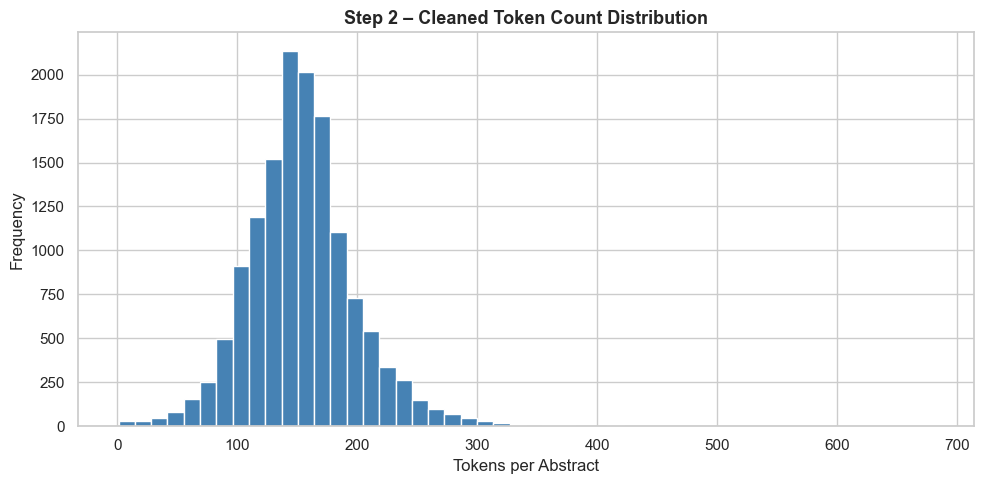

In [3]:
print("\n=== STEP 2: Preprocessing ===")
stop_words = set(stopwords.words('english'))

def preprocess_text(text):
    if pd.isna(text): return ""
    text = text.lower()
    text = re.sub(r'[^a-zA-Z\s]', '', text)
    tokens = word_tokenize(text)
    return " ".join([t for t in tokens if t not in stop_words and len(t) > 2])

tqdm.pandas()
print("Preprocessing abstracts …")
df['Cleaned_Abstract'] = df['Abstract'].progress_apply(preprocess_text)
df = df[df['Cleaned_Abstract'] != ""]

# Save CSV
df.to_csv(os.path.join(RES, 'step2_cleaned_corpus.csv'), index=False)

# Graph 2: Token length distribution after cleaning
df['clean_length'] = df['Cleaned_Abstract'].apply(lambda x: len(x.split()))
fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(df['clean_length'], bins=50, color='steelblue', edgecolor='white')
ax.set_title('Step 2 – Cleaned Token Count Distribution', fontweight='bold', fontsize=13)
ax.set_xlabel('Tokens per Abstract')
ax.set_ylabel('Frequency')
plt.tight_layout()
plt.savefig(os.path.join(RES, 'step2_preprocessing_stats.png'), dpi=150)
plt.show()


## Step 3: BioBERT Feature Extraction
We use a pre-trained BioBERT model to extract dense semantic embeddings for each document.


=== STEP 3: BioBERT Feature Extraction ===
Loading dmis-lab/biobert-v1.1...


Loading weights: 100%|██████████| 199/199 [00:00<00:00, 30042.35it/s]


Extracting dense embeddings (this may take a while)...


100%|██████████| 440/440 [35:47<00:00,  4.88s/it] 


BioBERT matrix shape: (14064, 768)


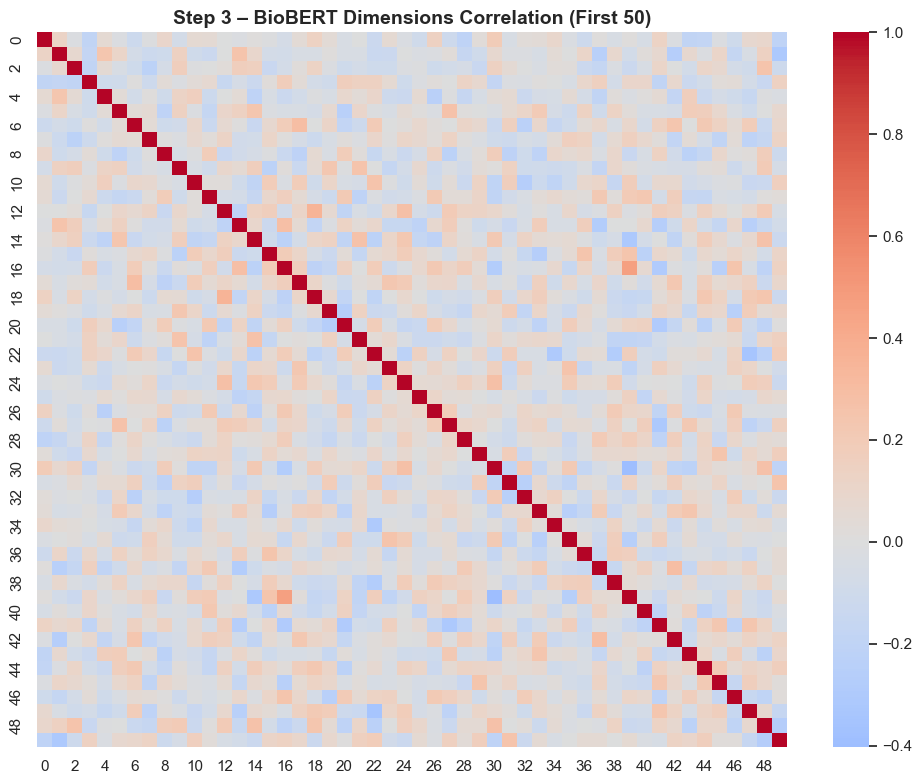

In [4]:
print("\n=== STEP 3: BioBERT Feature Extraction ===")
# Define BioBERT model
MODEL_NAME = "dmis-lab/biobert-v1.1"
print(f"Loading {MODEL_NAME}...")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModel.from_pretrained(MODEL_NAME)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model.to(device)
model.eval()

# Extract Embeddings in batches
BATCH_SIZE = 32
texts = df['Cleaned_Abstract'].tolist()
embeddings = []

print("Extracting dense embeddings (this may take a while)...")
with torch.no_grad():
    for i in tqdm(range(0, len(texts), BATCH_SIZE)):
        batch_texts = texts[i:i+BATCH_SIZE]
        inputs = tokenizer(batch_texts, padding=True, truncation=True, max_length=128, return_tensors="pt").to(device)
        outputs = model(**inputs)
        # Use mean pooling of the last hidden state
        attention_mask = inputs['attention_mask'].unsqueeze(-1).expand(outputs.last_hidden_state.size()).float()
        sum_embeddings = torch.sum(outputs.last_hidden_state * attention_mask, 1)
        sum_mask = torch.clamp(attention_mask.sum(1), min=1e-9)
        mean_pooled = sum_embeddings / sum_mask
        embeddings.append(mean_pooled.cpu().numpy())

embeddings_matrix = np.vstack(embeddings)
X_norm = normalize(embeddings_matrix, norm='l2')

print(f"BioBERT matrix shape: {embeddings_matrix.shape}")

# Save sample CSV
pd.DataFrame(embeddings_matrix[:100]).to_csv(os.path.join(RES, 'step3_biobert_sample.csv'), index=False)

# Graph 3: Correlation matrix of first 50 embedding dimensions
corr_mat = np.corrcoef(X_norm[:500, :50].T)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr_mat, cmap='coolwarm', center=0, ax=ax)
ax.set_title('Step 3 – BioBERT Dimensions Correlation (First 50)', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig(os.path.join(RES, 'step3_biobert_correlation.png'), dpi=150)
plt.show()


## Step 4: Contrastive Learning (Self-Supervised)
Generate pseudo-anchors using KMeans (K=10) and compute inter-concept similarity.


=== STEP 4: Contrastive Learning ===


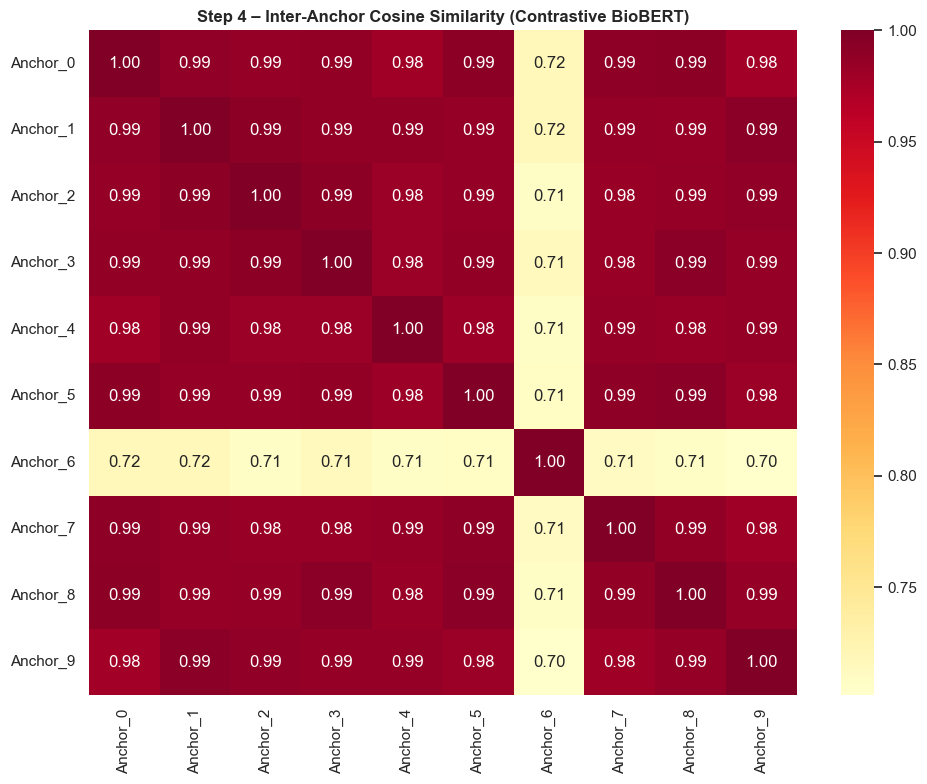

In [5]:
print("\n=== STEP 4: Contrastive Learning ===")
km_pseudo = KMeans(n_clusters=10, random_state=42, n_init=5)
pseudo_labels = km_pseudo.fit_predict(X_norm)

unique_concepts = np.unique(pseudo_labels)
centroids = {}
for concept in unique_concepts:
    mask = pseudo_labels == concept
    centroids[concept] = np.asarray(X_norm[mask].mean(axis=0)).flatten()

centroid_matrix = np.stack([centroids[c] for c in unique_concepts])
sim_matrix = cosine_similarity(centroid_matrix)
sim_df = pd.DataFrame(sim_matrix, index=[f'Anchor_{c}' for c in unique_concepts], 
                      columns=[f'Anchor_{c}' for c in unique_concepts])
sim_df.to_csv(os.path.join(RES, 'step4_inter_concept_similarity.csv'))

# Graph 4: Contrastive Similarity Heatmap
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(sim_df.values, xticklabels=sim_df.columns, yticklabels=sim_df.index,
            annot=True, fmt='.2f', cmap='YlOrRd', ax=ax)
ax.set_title('Step 4 – Inter-Anchor Cosine Similarity (Contrastive BioBERT)', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RES, 'step4_inter_concept_similarity.png'), dpi=150)
plt.show()


## Step 5: UMAP Dimensionality Reduction


=== STEP 5: UMAP Dimensionality Reduction ===
Fitting 2-D UMAP …


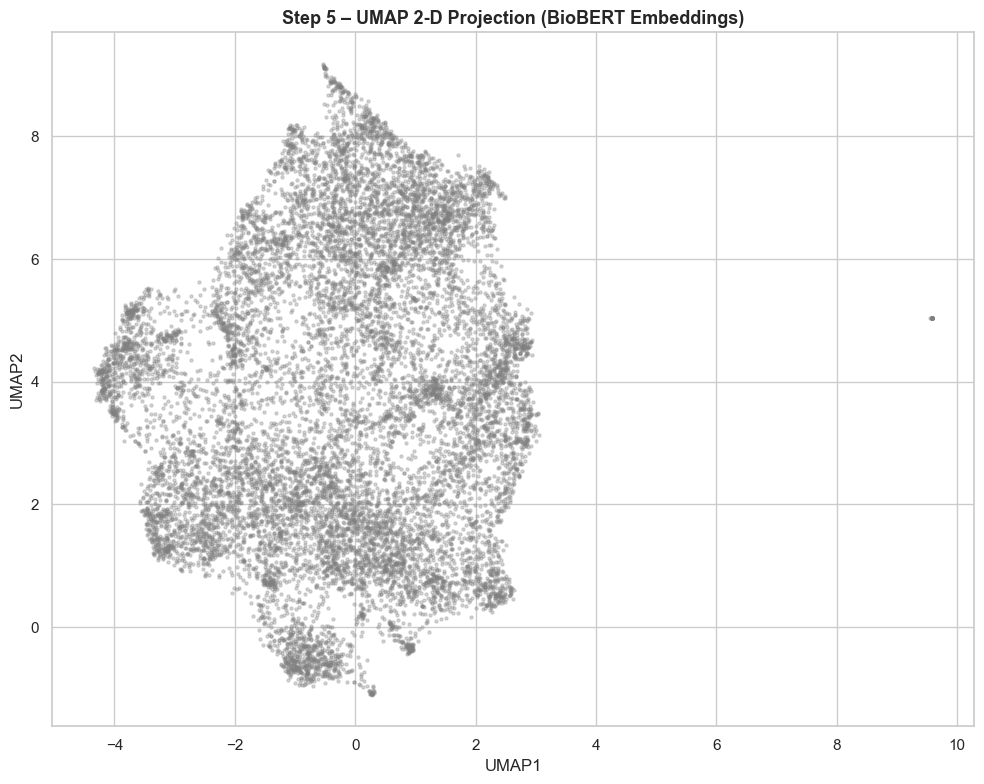

In [6]:
print("\n=== STEP 5: UMAP Dimensionality Reduction ===")
reducer_2d = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1, metric='cosine', random_state=42)
print("Fitting 2-D UMAP …")
embedding_2d = reducer_2d.fit_transform(X_norm)

umap_df = pd.DataFrame(embedding_2d, columns=['UMAP1', 'UMAP2'])
umap_df.to_csv(os.path.join(RES, 'step5_umap_embeddings.csv'), index=False)

# Graph 5: Raw UMAP
fig, ax = plt.subplots(figsize=(10, 8))
ax.scatter(embedding_2d[:, 0], embedding_2d[:, 1], alpha=0.3, s=5, color='gray')
ax.set_title('Step 5 – UMAP 2-D Projection (BioBERT Embeddings)', fontsize=13, fontweight='bold')
ax.set_xlabel('UMAP1'); ax.set_ylabel('UMAP2')
plt.tight_layout()
plt.savefig(os.path.join(RES, 'step5_umap2d_unlabeled.png'), dpi=150)
plt.show()


## Step 6: Automated K Selection & Clustering


=== STEP 6: Automated K Selection & Clustering ===
Running Elbow Method...

--> Automatically determined Optimal K = 5


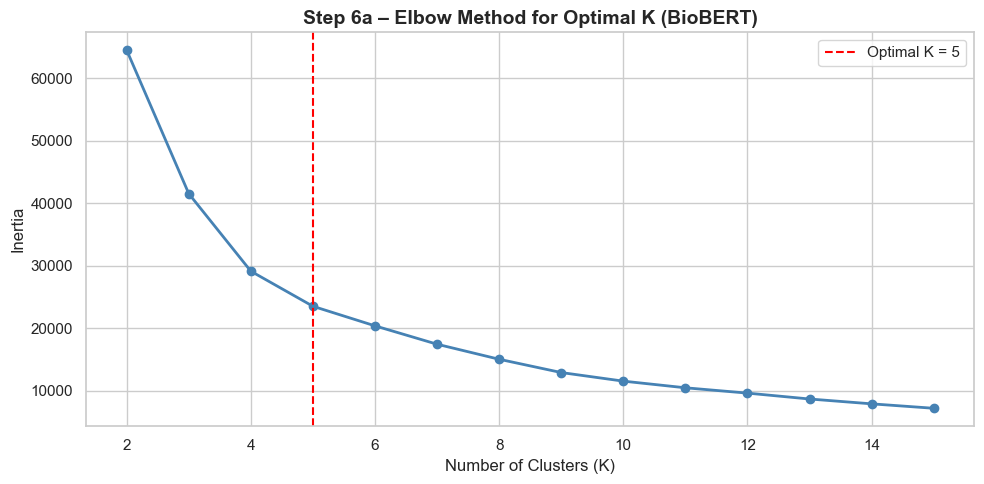

Running KMeans (K=5)...
Running HDBSCAN...
Running Hierarchical Clustering (K=5)...


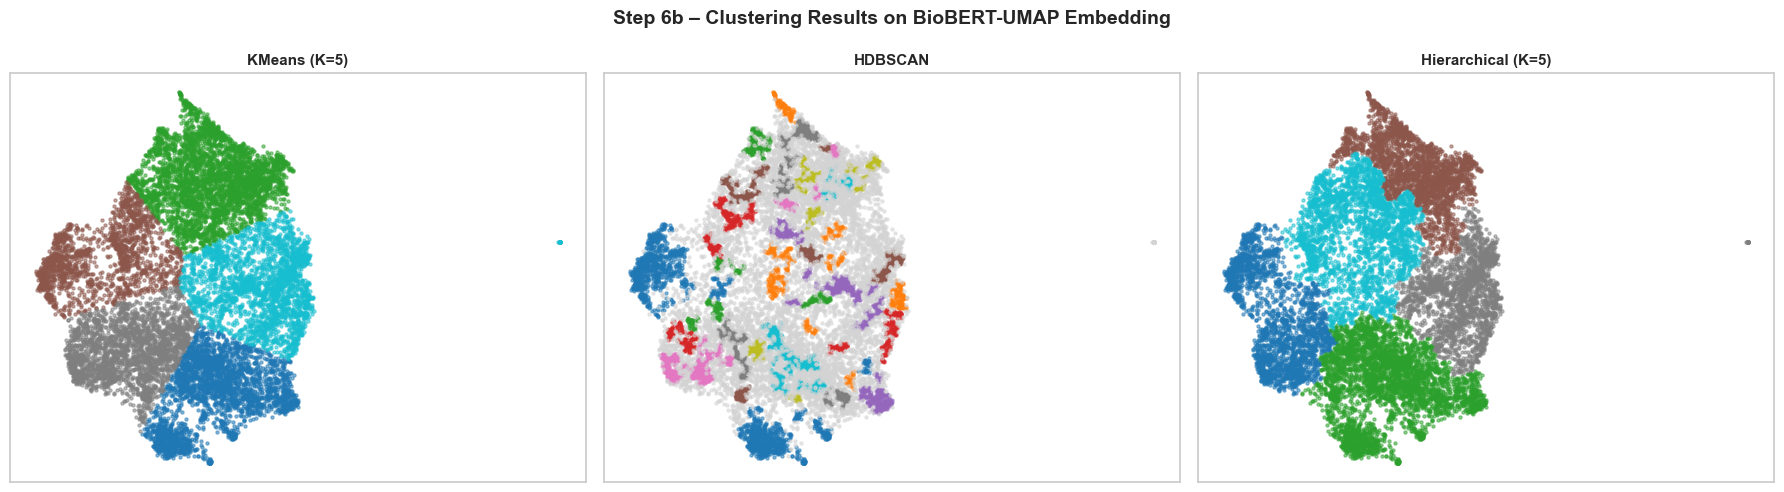

In [7]:
print("\n=== STEP 6: Automated K Selection & Clustering ===")

inertias = []
k_range = list(range(2, 16))
print("Running Elbow Method...")
for k in k_range:
    km_tmp = KMeans(n_clusters=k, random_state=42, n_init=10)
    km_tmp.fit(embedding_2d)
    inertias.append(km_tmp.inertia_)

p1 = np.array([k_range[0], inertias[0]])
p2 = np.array([k_range[-1], inertias[-1]])
distances = []
for i in range(len(k_range)):
    p0 = np.array([k_range[i], inertias[i]])
    dist = np.abs(np.cross(p2 - p1, p1 - p0)) / np.linalg.norm(p2 - p1)
    distances.append(dist)

OPTIMAL_K = k_range[np.argmax(distances)]
print(f"\n--> Automatically determined Optimal K = {OPTIMAL_K}")

# Graph 6a: Elbow Method
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(k_range, inertias, marker='o', color='steelblue', lw=2)
ax.axvline(OPTIMAL_K, ls='--', color='red', label=f'Optimal K = {OPTIMAL_K}')
ax.set_title('Step 6a – Elbow Method for Optimal K (BioBERT)', fontweight='bold', fontsize=14)
ax.set_xlabel('Number of Clusters (K)'); ax.set_ylabel('Inertia')
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(RES, 'step6a_automated_elbow_method.png'), dpi=150)
plt.show()

# Clustering
N_CLUSTERS = OPTIMAL_K
print(f"Running KMeans (K={N_CLUSTERS})...")
km = KMeans(n_clusters=N_CLUSTERS, random_state=42, n_init=20)
km_labels = km.fit_predict(embedding_2d)

print("Running HDBSCAN...")
hdb = hdbscan.HDBSCAN(min_cluster_size=30, min_samples=5, metric='euclidean')
hdb_labels = hdb.fit_predict(embedding_2d)

print(f"Running Hierarchical Clustering (K={N_CLUSTERS})...")
hc = AgglomerativeClustering(n_clusters=N_CLUSTERS, linkage='ward')
hc_labels = hc.fit_predict(embedding_2d)

df['KMeans_Cluster'] = km_labels
df['HDBSCAN_Cluster'] = hdb_labels
df['Hierarchical_Cluster'] = hc_labels
df[['PMID', 'KMeans_Cluster', 'HDBSCAN_Cluster', 'Hierarchical_Cluster']].to_csv(
    os.path.join(RES, 'step6_cluster_assignments.csv'), index=False)

# Graph 6b: Sub-plots of Clusters
def plot_clusters(ax, emb, labels, title):
    unique = set(labels)
    cmap = plt.get_cmap('tab10', max(len(unique), 1))
    for i, cid in enumerate(unique):
        mask = labels == cid
        color = 'lightgray' if cid == -1 else cmap(i/len(unique))
        ax.scatter(emb[mask, 0], emb[mask, 1], c=[color], alpha=0.5, s=5)
    ax.set_title(title, fontsize=11, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
plot_clusters(axes[0], embedding_2d, km_labels, f'KMeans (K={N_CLUSTERS})')
plot_clusters(axes[1], embedding_2d, hdb_labels, 'HDBSCAN')
plot_clusters(axes[2], embedding_2d, hc_labels, f'Hierarchical (K={N_CLUSTERS})')
plt.suptitle('Step 6b – Clustering Results on BioBERT-UMAP Embedding', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RES, 'step6b_cluster_umap_all.png'), dpi=150)
plt.show()


## Step 7: BERTopic / Topic Analysis
Since BioBERT outputs dense embeddings, we use CountVectorizer to extract textual topics for each cluster.


=== STEP 7: Topic Analysis ===


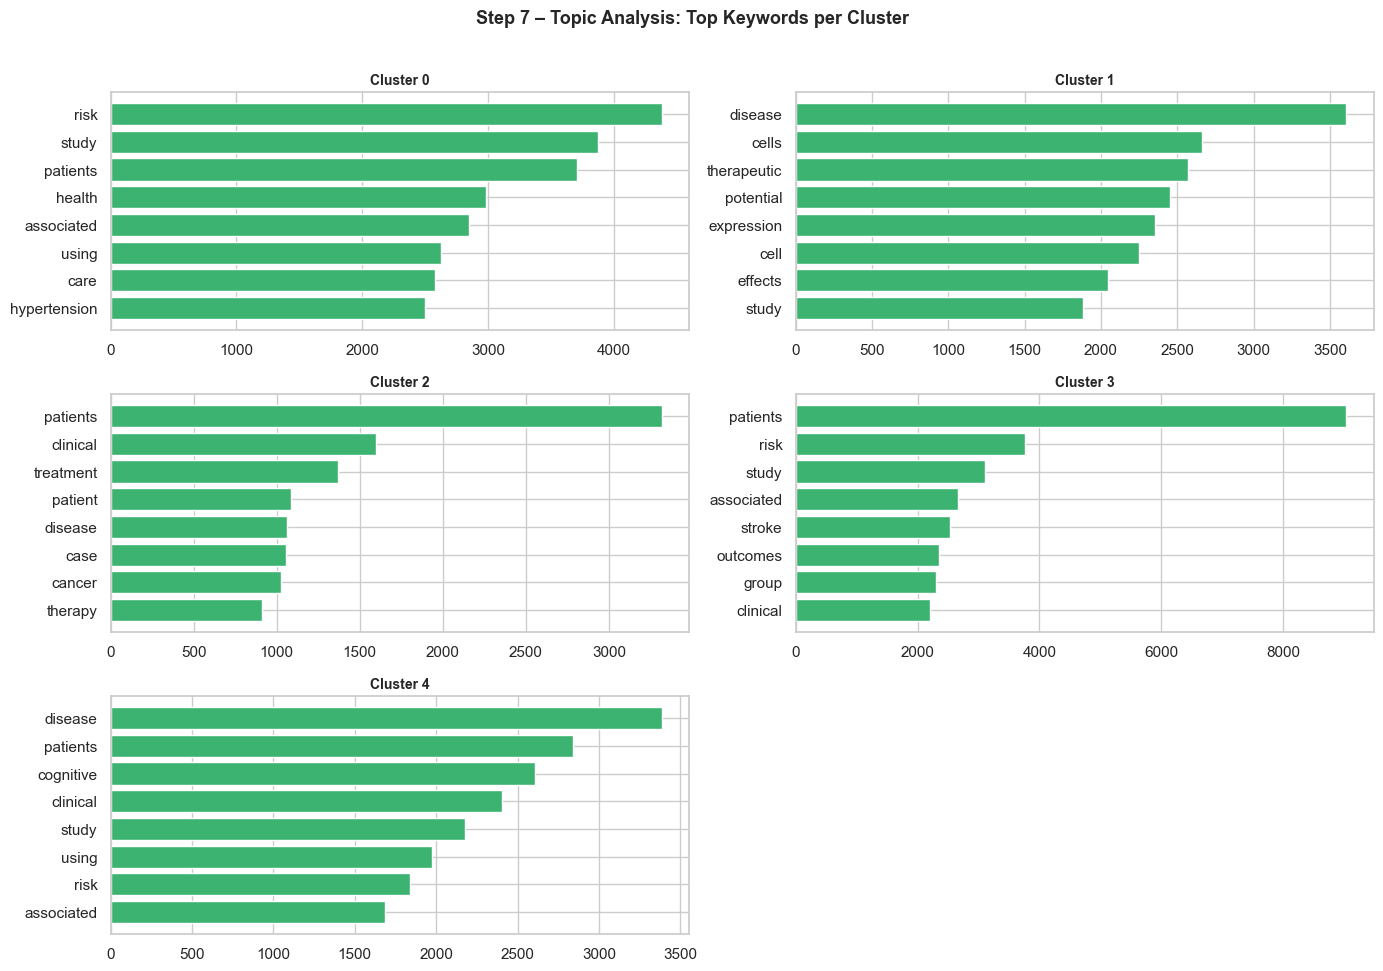

In [8]:
print("\n=== STEP 7: Topic Analysis ===")
topic_records = []
for cluster_id in sorted(set(km_labels)):
    mask = km_labels == cluster_id
    texts = df.loc[mask, 'Cleaned_Abstract'].values
    if len(texts) < 5: continue
    cv = CountVectorizer(max_features=500, min_df=2, stop_words='english')
    try:
        cv_mat = cv.fit_transform(texts)
    except ValueError:
        continue
    freq = np.asarray(cv_mat.sum(axis=0)).flatten()
    words = cv.get_feature_names_out()
    top_idx = freq.argsort()[-15:][::-1]
    
    for rank, idx in enumerate(top_idx):
        topic_records.append({'Cluster': cluster_id, 'Rank': rank + 1, 'Topic_Keyword': words[idx], 'Frequency': int(freq[idx])})

topic_df = pd.DataFrame(topic_records)
topic_df.to_csv(os.path.join(RES, 'step7_topic_keywords_per_cluster.csv'), index=False)

# Graph 7: Topic keywords per cluster
clusters = topic_df['Cluster'].unique()
ncols = 2
nrows = int(np.ceil(len(clusters) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(14, nrows * 3.2))
axes = axes.flatten()
for i, cid in enumerate(clusters):
    sub = topic_df[topic_df['Cluster'] == cid].head(8)
    axes[i].barh(sub['Topic_Keyword'][::-1], sub['Frequency'][::-1], color='mediumseagreen')
    axes[i].set_title(f'Cluster {cid}', fontsize=10, fontweight='bold')
for j in range(i+1, len(axes)): axes[j].set_visible(False)
plt.suptitle('Step 7 – Topic Analysis: Top Keywords per Cluster', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig(os.path.join(RES, 'step7_topic_keywords_grid.png'), dpi=150, bbox_inches='tight')
plt.show()


## Step 8: Evaluation Metrics


=== STEP 8: Evaluation Metrics ===
   Silhouette  Davies_Bouldin        Method
0      0.4112          0.8124        KMeans
1      0.4225          0.7068       HDBSCAN
2      0.3660          0.8845  Hierarchical


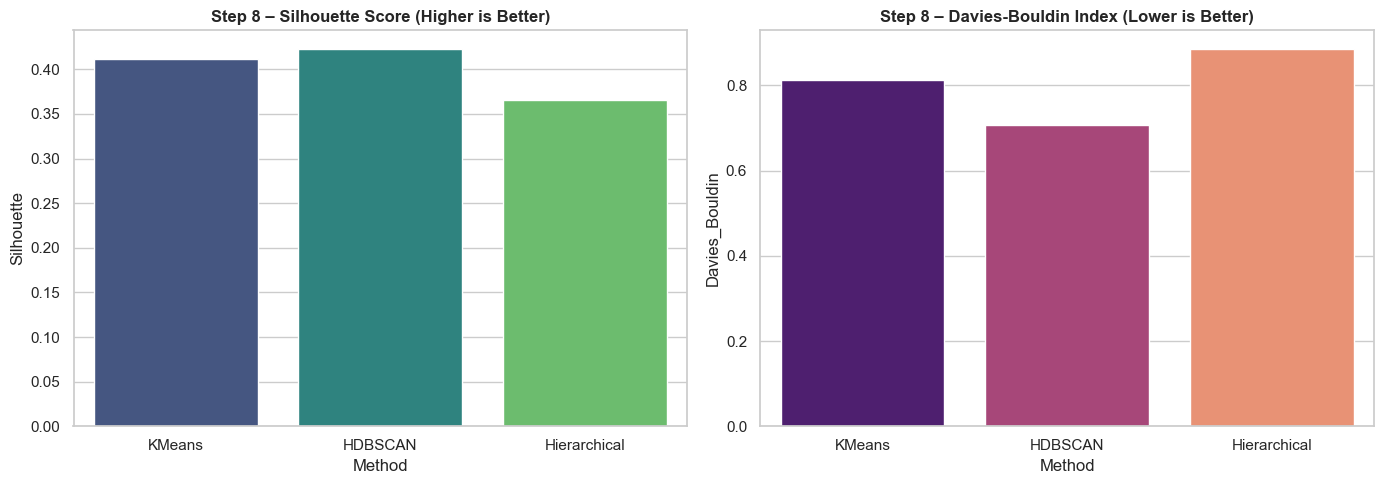

In [9]:
print("\n=== STEP 8: Evaluation Metrics ===")

def eval_metrics_unsup(emb, pred):
    valid = pred != -1
    if valid.sum() < 2 or len(set(pred[valid])) < 2:
        return {'Silhouette': np.nan, 'Davies_Bouldin': np.nan}
    return {
        'Silhouette': round(silhouette_score(emb[valid], pred[valid]), 4),
        'Davies_Bouldin': round(davies_bouldin_score(emb[valid], pred[valid]), 4)
    }

methods = {'KMeans': km_labels, 'HDBSCAN': hdb_labels, 'Hierarchical': hc_labels}
eval_rows = []
for name, pred in methods.items():
    m = eval_metrics_unsup(embedding_2d, pred)
    m['Method'] = name
    eval_rows.append(m)

eval_df = pd.DataFrame(eval_rows)
eval_df.to_csv(os.path.join(RES, 'step8_evaluation_metrics.csv'), index=False)
print(eval_df)

# Graph 8: Evaluation Metrics Bar Chart
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(data=eval_df, x='Method', y='Silhouette', palette='viridis', ax=axes[0])
axes[0].set_title('Step 8 – Silhouette Score (Higher is Better)', fontweight='bold')

sns.barplot(data=eval_df, x='Method', y='Davies_Bouldin', palette='magma', ax=axes[1])
axes[1].set_title('Step 8 – Davies-Bouldin Index (Lower is Better)', fontweight='bold')

plt.tight_layout()
plt.savefig(os.path.join(RES, 'step8_evaluation_metrics.png'), dpi=150)
plt.show()


## Step 9: Keyword Extraction per Cluster
Extracting distinct TF-IDF keywords for each cluster to interpret the BioBERT representations.


=== STEP 9: Keyword Extraction per Cluster ===


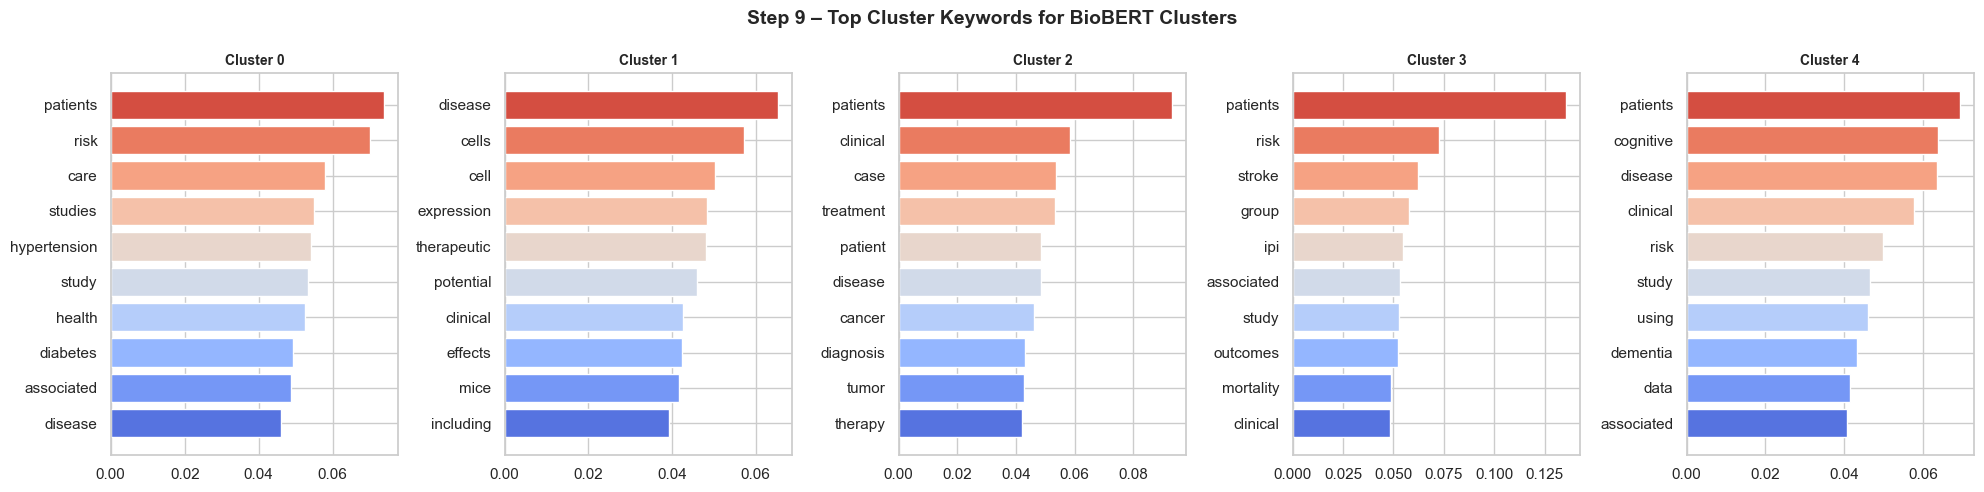

In [10]:
print("\n=== STEP 9: Keyword Extraction per Cluster ===")
kw_cluster_records = []
for cid in sorted(set(km_labels)):
    mask = km_labels == cid
    cluster_texts = df.loc[mask, 'Cleaned_Abstract'].values
    cluster_tfidf = TfidfVectorizer(max_features=200, min_df=1, stop_words='english')
    try:
        mat = cluster_tfidf.fit_transform(cluster_texts)
    except ValueError: continue
    mean_scores = np.asarray(mat.mean(axis=0)).flatten()
    top_idx = mean_scores.argsort()[-15:][::-1]
    feats = cluster_tfidf.get_feature_names_out()
    
    for rank, idx in enumerate(top_idx):
        kw_cluster_records.append({'Cluster': cid, 'Rank': rank + 1, 'Keyword': feats[idx], 'TF_IDF_Score': round(mean_scores[idx], 6)})

kw_cluster_df = pd.DataFrame(kw_cluster_records)
kw_cluster_df.to_csv(os.path.join(RES, 'step9_keywords_per_cluster.csv'), index=False)

# Graph 9: Keyword scores
fig, axes = plt.subplots(1, len(set(km_labels)), figsize=(20, 5))
for i, cid in enumerate(sorted(set(km_labels))):
    sub = kw_cluster_df[kw_cluster_df['Cluster'] == cid].head(10)
    axes[i].barh(sub['Keyword'][::-1], sub['TF_IDF_Score'][::-1], color=sns.color_palette("coolwarm", 10))
    axes[i].set_title(f'Cluster {cid}', fontsize=10, fontweight='bold')
plt.suptitle('Step 9 – Top Cluster Keywords for BioBERT Clusters', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(RES, 'step9_cluster_keywords.png'), dpi=150, bbox_inches='tight')
plt.show()


## Step 10: Automated Disease Knowledge Mapping
Generating dynamic disease names for each cluster based on its top keywords.


=== STEP 10: Automated Disease Knowledge Mapping ===


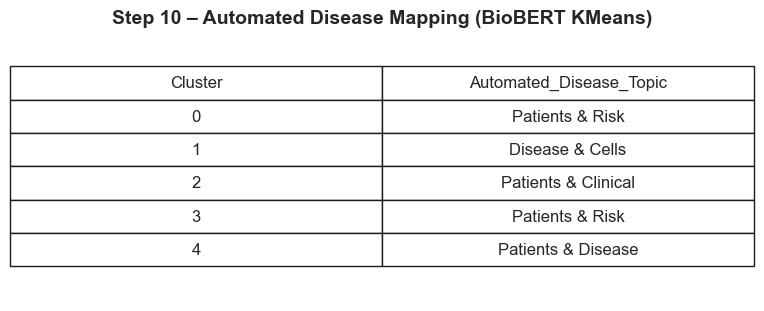

In [11]:
print("\n=== STEP 10: Automated Disease Knowledge Mapping ===")

def map_clusters_to_keywords(labels):
    mapping = {}
    for cid in set(labels):
        if cid == -1:
            mapping[cid] = "Noise"
            continue
        mask = labels == cid
        texts = df.loc[mask, 'Cleaned_Abstract'].values
        vec = TfidfVectorizer(max_features=100, stop_words='english')
        try:
            mat = vec.fit_transform(texts)
            scores = np.asarray(mat.mean(axis=0)).flatten()
            top_words = vec.get_feature_names_out()[scores.argsort()[-2:][::-1]]
            disease_name = " & ".join([w.title() for w in top_words])
            mapping[cid] = disease_name
        except:
            mapping[cid] = f"Topic {cid}"
    return mapping

km_mapping = map_clusters_to_keywords(km_labels)
hdb_mapping = map_clusters_to_keywords(hdb_labels)
hc_mapping = map_clusters_to_keywords(hc_labels)

mapped_df = pd.DataFrame(list(km_mapping.items()), columns=['Cluster', 'Automated_Disease_Topic'])
mapped_df.to_csv(os.path.join(RES, 'step10_disease_knowledge_mapping.csv'), index=False)

# Graph 10: Mapping visualization (Table Plot)
fig, ax = plt.subplots(figsize=(8, len(mapped_df)*0.5 + 1))
ax.axis('off')
table = ax.table(cellText=mapped_df.values, colLabels=mapped_df.columns, loc='center', cellLoc='center')
table.auto_set_font_size(False)
table.set_fontsize(12)
table.scale(1.2, 2)
plt.title('Step 10 – Automated Disease Mapping (BioBERT KMeans)', fontweight='bold', fontsize=14)
plt.savefig(os.path.join(RES, 'step10_disease_knowledge_mapping.png'), dpi=150, bbox_inches='tight')
plt.show()


## Step 11: Final Visualization (UMAP plot)


=== STEP 11: Final Visualization ===


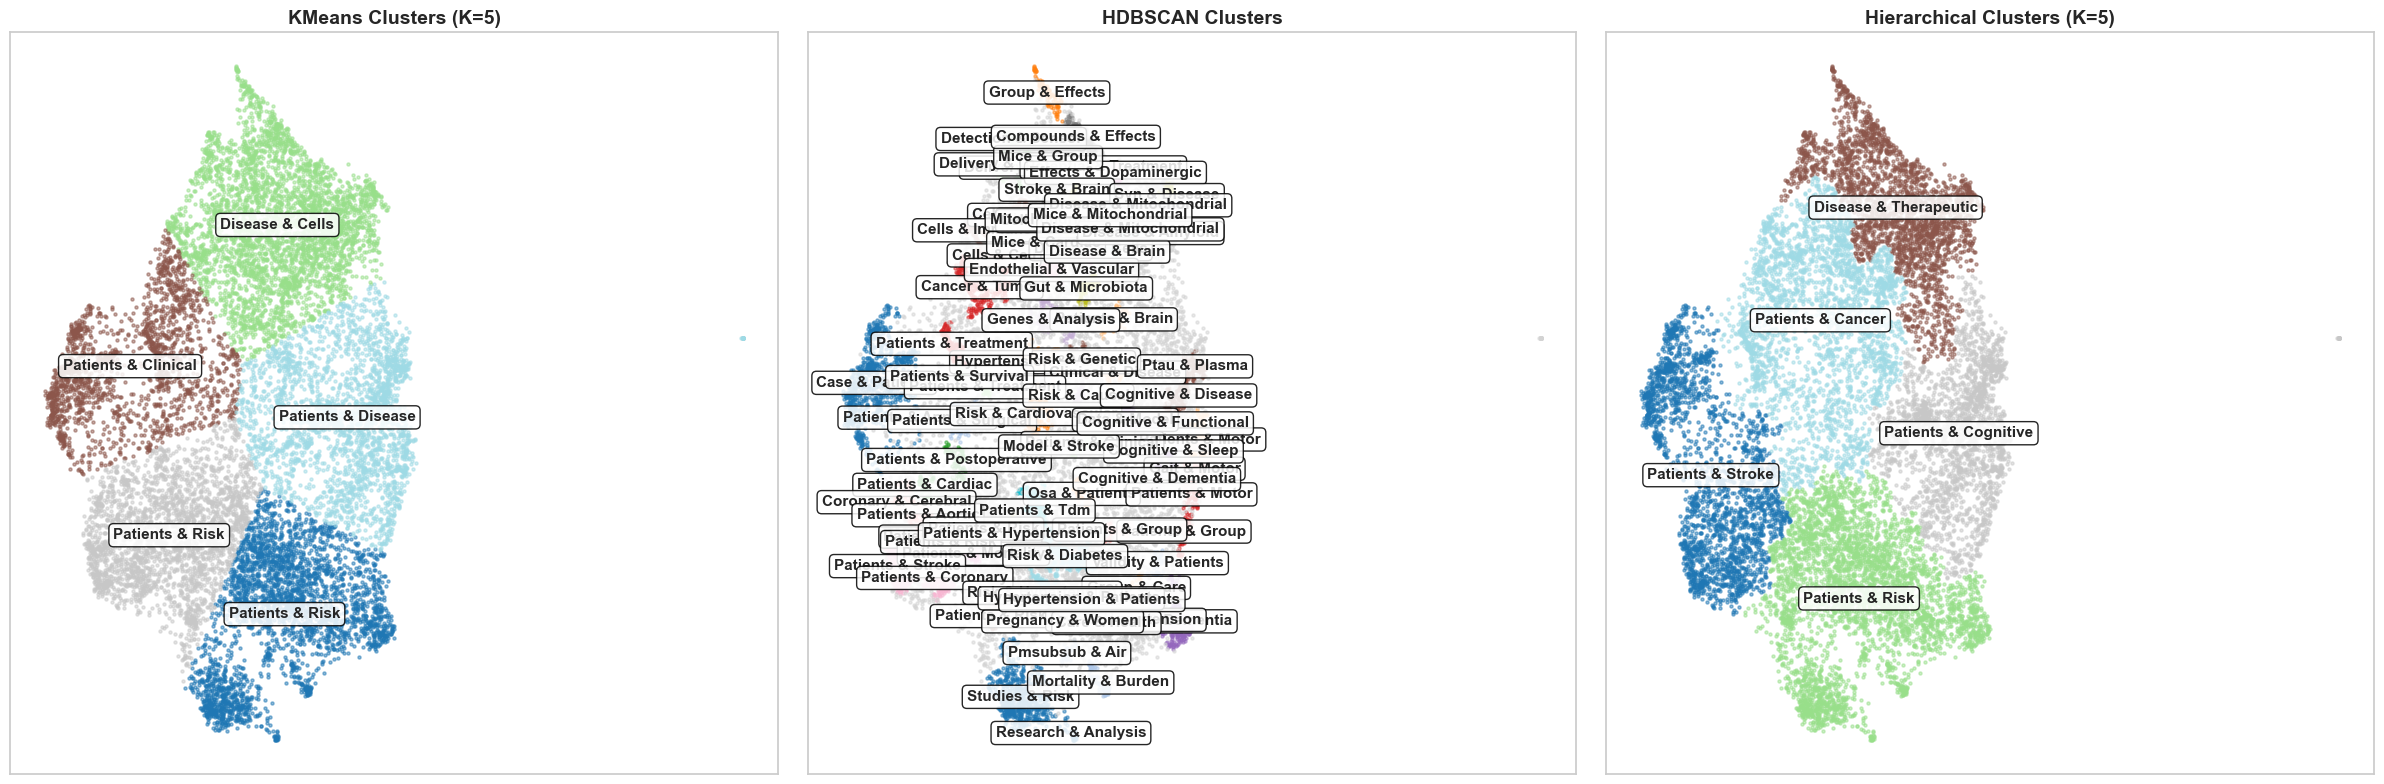

Pipeline Complete! All CSVs and graphs saved successfully to BioBERT Results


In [12]:
print("\n=== STEP 11: Final Visualization ===")

def plot_mapped_umap(ax, emb, labels, mapping, title):
    unique_clusters = set(labels)
    cmap = plt.get_cmap('tab20', max(len(unique_clusters), 1))
    
    for i, cid in enumerate(unique_clusters):
        mask = (labels == cid)
        color = 'lightgray' if cid == -1 else cmap(i / len(unique_clusters))
        label_name = mapping[cid]
        ax.scatter(emb[mask, 0], emb[mask, 1], c=[color], alpha=0.5, s=5)
        
        if cid != -1:
            centroid_x = emb[mask, 0].mean()
            centroid_y = emb[mask, 1].mean()
            ax.text(centroid_x, centroid_y, label_name, 
                    fontsize=11, fontweight='bold', ha='center', va='center',
                    bbox=dict(facecolor='white', alpha=0.85, edgecolor='black', boxstyle='round,pad=0.3'))
            
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xticks([]); ax.set_yticks([])

fig, axes = plt.subplots(1, 3, figsize=(24, 8))
axes = axes.flatten()

plot_mapped_umap(axes[0], embedding_2d, km_labels, km_mapping, f"KMeans Clusters (K={N_CLUSTERS})")
plot_mapped_umap(axes[1], embedding_2d, hdb_labels, hdb_mapping, "HDBSCAN Clusters")
plot_mapped_umap(axes[2], embedding_2d, hc_labels, hc_mapping, f"Hierarchical Clusters (K={N_CLUSTERS})")

plt.tight_layout()
plt.savefig(os.path.join(RES, 'step11_final_mapped_umap_all_algorithms.png'), dpi=200, bbox_inches='tight')
plt.show()

print("Pipeline Complete! All CSVs and graphs saved successfully to", RES)
